# Libraries

In [1]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Dataset

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

In [3]:
features_individual = ['sex', 'age']
features_school = ['failures', 'school', 'studytime']
features_family = ['Medu', 'Fedu', 'address', 'internet']
features_external = ['higher', 'Dalc', 'reason_reputation']
features_score = ["G1"]

In [4]:
df = df_raw.copy()
independent_variables = features_individual + features_school + features_family + features_external + features_score
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]

# Leaving out outliers

Given the results of Simple Linear Regression, only people who quit (G3 results = 0 or 1) will be considered outliers, since they did not perform the test or did not even study, altering the dataset.

In [5]:
print(df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print(df.shape)

(649, 14)
(633, 14)


A logistic regression will be attempted in order to predict the probability of a student quitting

# Regression

In [6]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.787
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     176.4
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          3.62e-198
Time:                        20:48:17   Log-Likelihood:                -1026.1
No. Observations:                 633   AIC:                             2080.
Df Residuals:                     619   BIC:                             2143.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.6793      0.78

# Refined model (only statistically significant variables)

Removing variables

In [28]:
features_individual = ['age']
features_school = ['failures']
features_family = ['Medu']
features_external = ['higher']
features_score = ["G1"]

In [29]:
df = df_raw.copy()
df = df.loc[~(df_raw["G3"] <= 1)]
independent_variables = features_individual + features_school + features_family + features_external + features_score
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]

In [30]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     456.6
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          3.01e-206
Time:                        21:02:34   Log-Likelihood:                -1030.4
No. Observations:                 633   AIC:                             2073.
Df Residuals:                     627   BIC:                             2100.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9029      0.762     -2.496      0.0

In [32]:
std_y = y.std()
std_x = df[independent_variables].std()

beta = model.params[independent_variables] * std_x / std_y

coefficients = pd.DataFrame({
    "B": model.params[independent_variables],
    "Beta": beta,
    "P-value": model.pvalues[independent_variables]
})

print(coefficients.sort_values(
    "Beta",
    key=abs,
    ascending=False
))

                 B      Beta        P-value
G1        0.822057  0.830028  1.812793e-170
age       0.270450  0.123580   7.851166e-10
failures -0.391757 -0.085377   5.257333e-05
higher   -0.477946 -0.054274   8.299131e-03
Medu      0.102687  0.043809   2.444365e-02


In [33]:
vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

   Variable         VIF
0     const  239.921856
1       age    1.139793
2  failures    1.279239
3      Medu    1.097799
4    higher    1.222419
5        G1    1.308988


## Checking assumptions

### Residuals

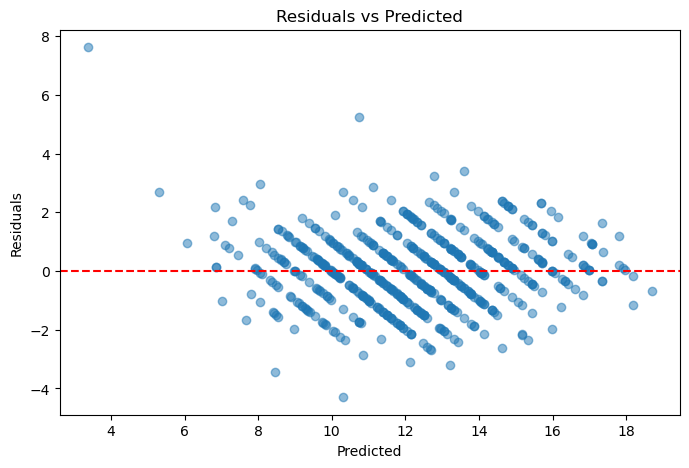

In [34]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

### Independence of errors

In [35]:
dw = durbin_watson(model.resid)

print(f"Durbin-Watson: {dw:.2f}")

Durbin-Watson: 1.60


### Homoscedasticity

In [36]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(32.02589319985656), 'LM p-value': np.float64(5.8715264456577225e-06), 'F Statistic': np.float64(6.682562462874245), 'F p-value': np.float64(4.455889458908024e-06)}


Data are still heteroscedastic.

With the robust regression, the feature `Medu loses statistical significance`. However, since the *p-value* is 0.051 and the variable has a theoretical foundation, it will not be omitted

In [37]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.785
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     361.8
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          4.60e-182
Time:                        21:04:41   Log-Likelihood:                -1030.4
No. Observations:                 633   AIC:                             2073.
Df Residuals:                     627   BIC:                             2100.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9029      0.752     -2.530      0.0

### Normality of residuals

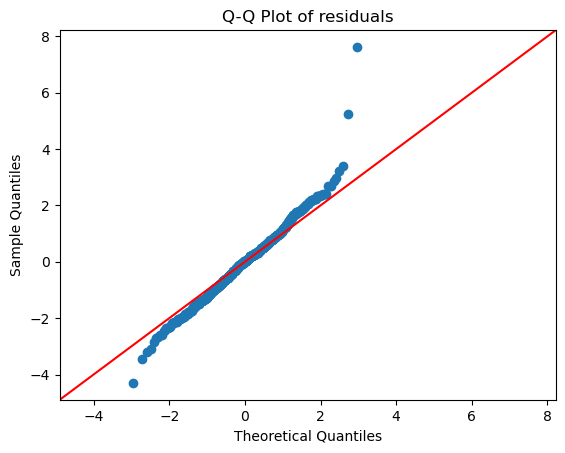

In [38]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [39]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.9809060053265579
P-value: 2.384339480558543e-07


Again, the assumption of normality of residuals is violated

# Conclusions

> Model

The `model cannot predict if a student will quit`.\
The model predicts the effects on final grade by:
* age = *older student will have a higher score (almost 0.3 points/year increase)*
* failures = *students who failed previously will have lower scores (almost 0.4 points)*
* Medu = *student with educated mothers will perform better (almost 0.1 points per category increase)*
* higher = *student who want to take higher education will perform better (almost 0.5 points)*
* G1 = *first period grade is the foundation of the final grade (almost 80% of final grade)*

## RMSE and MAE

In [40]:
y_pred = model.predict(X)

mae_in = mean_absolute_error(y, y_pred)
rmse_in = np.sqrt(mean_squared_error(y, y_pred))

print("MAE in-sample:", round(mae_in, 3))
print("RMSE in-sample:", round(rmse_in, 3))

MAE in-sample: 0.95
RMSE in-sample: 1.232


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_train = sm.OLS(y_train, X_train).fit()

y_pred_test = model_train.predict(X_test)

mae_out = mean_absolute_error(y_test, y_pred_test)
rmse_out = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("MAE out-of-sample:", round(mae_out, 3))
print("RMSE out-of-sample:", round(rmse_out, 3))

MAE out-of-sample: 0.967
RMSE out-of-sample: 1.247


In [42]:
results = pd.DataFrame({
    'MAE': [mae_in, mae_out],
    'RMSE': [rmse_in, rmse_out]
}, index=['In-sample', 'Out-of-sample'])

display(round(results, 3))

,MAE,RMSE
In-sample,0.950,1.232
Out-of-sample,0.967,1.247


For the ratio between in-sample and out-of-sample.

$\delta$% = $\frac{OOS - IS}{IS} * 100$

where OOS = Out-of-sample, IS = In-sample

| $\delta$%        | Indicative interpretation       |
|------------------|---------------------------------|
| 0 - 5            | Optimal stability               |
| 5 - 10           | Good stability                  |
| 10 - 20          | Possible overfitting            |
| 20 - 30          | Likely overfitting              |
| > 30             | Significant overfitting         |

| Ratio RMSE / MAE | Indicative interpretation       |
|------------------|---------------------------------|
| 1.00 - 1.10      | Homogeneous errors              |
| 1.10 - 1.25      | Possible large errors           |
| 1.25 - 1.50      | Some large errors               |
| 1.50 - 2.00      | Very large errors               |
| > 2              | Large influence of large errors |

In [43]:
print("delta MAE:",
      round((mae_out - mae_in) / mae_in * 100, 2)
)
print("delta RMSE:",
      round((rmse_out - rmse_in) / rmse_in * 100, 2)
)

print("Ratio RMSE/MAE in-sample:",
      round(rmse_in / mae_in, 2)
)

print("Ratio RMSE/MAE out-of-sample:",
      round(rmse_out / mae_out, 2)
)

delta MAE: 1.72
delta RMSE: 1.18
Ratio RMSE/MAE in-sample: 1.3
Ratio RMSE/MAE out-of-sample: 1.29


Optimal stability but some large errors

To check large errors

MAE: 0.9666356061536878
90° percentile: 2.0147812383090975
95° percentile: 2.3590688566011835
Max error: 4.336223139269105


<Axes: ylabel='Count'>

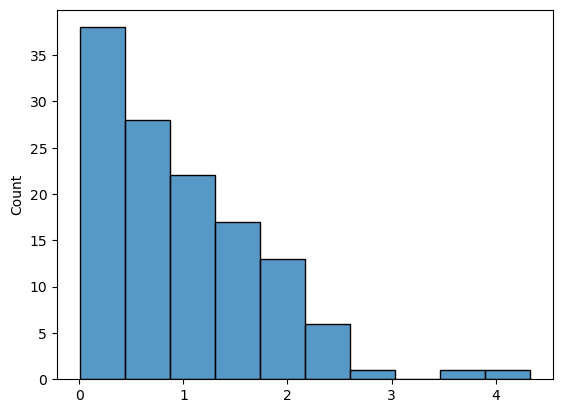

In [44]:
errors = np.abs(y_test - y_pred_test)

print("MAE:", errors.mean())
print("90° percentile:", np.percentile(errors, 90))
print("95° percentile:", np.percentile(errors, 95))
print("Max error:", errors.max())
sns.histplot(errors)